# Blinkit Dataset EDA and Delivery-Time Modeling

Step-by-step EDA following the supplied `Blinkit_Dataset_EDA.ipynb.txt` structure. Counts and charts are calculated from the provided CSV. Model features use the shared checkout-time-safe pipeline.


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "app").is_dir() and (PROJECT_ROOT.parent / "app").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from app.features import FEATURES, prepare_training_data
from app.training import train_and_save

sns.set_theme(style="whitegrid", palette="colorblind")
DATA_PATH = PROJECT_ROOT / "data" / "compressed_data (2).csv"
if not DATA_PATH.is_file():
    raise FileNotFoundError(f"Add the Blinkit CSV at {DATA_PATH}, or update DATA_PATH.")
raw = pd.read_csv(DATA_PATH)
print(f"Dataset: {DATA_PATH.name}")
print(f"Shape: {raw.shape[0]:,} rows x {raw.shape[1]} columns")


Dataset: compressed_data (2).csv
Shape: 52,750 rows x 18 columns


## SUMMARY OF THE DATASET

The dataset contains grocery orders from multiple cities, including basket information, payment and fulfilment fields, and an observed delivery duration. Check the reference EDA counts against the supplied file instead of assuming it is unchanged.

## Columns Description

- **Order and time:** `order_id`, `order_date`, `order_hour`
- **Location and fulfilment:** `city`, `dark_store_id`, `delivery_partner_id`, `distance_km`, `order_status`
- **Basket and payment:** `category`, `quantity`, `unit_price`, `order_value`, `payment_mode`
- **Delivery outcome:** `promised_delivery_mins`, `actual_delivery_mins`, `stockout_flag`, `customer_rating`

The prediction target is `actual_delivery_mins`. IDs and fields unavailable at checkout or known only after delivery are excluded from model predictors.


## Data Assessment (Load & Inspect)

In [2]:
display(raw.head())
quality = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing": raw.isna().sum(),
    "missing_pct": (raw.isna().mean() * 100).round(2),
    "unique": raw.nunique(dropna=True),
})
display(quality)
display(raw.describe(include="all").T)


,order_id,order_date,order_hour,city,dark_store_id,category,quantity,unit_price,order_value,distance_km,promised_delivery_mins,actual_delivery_mins,stockout_flag,order_status,delivery_partner_id,customer_id,payment_mode,customer_rating
0,BLK129901,2025-02-14,13.0,Bangalore,DS-BAN-02,Beverages,1.0,71.24,71.24,2.63,10,15.0,0,Delivered,DP1393,CUST21117,UPI,4.0
1,BLK133558,2025-05-02,10.0,Hyderabad,NaN,Snacks,1.0,29.07,29.07,3.39,10,18.3,0,Cancelled,NaN,CUST24840,Wallet,NaN
2,BLK116541,2025-05-12,12.0,Chennai,DS-CHE-02,Household,1.0,13.82,13.82,1.05,10,12.9,0,Delivered,DP1287,CUST24791,Card,3.9
3,BLK104569,2025-03-13,23.0,Bangalore,DS-BAN-02,Snacks,3.0,118.82,356.46,2.67,10,17.7,0,Cancelled,NaN,CUST21775,NaN,NaN
4,BLK113377,2025-06-10,14.0,Mumbai,DS-MUM-04,Instant Food,2.0,18.50,37.00,1.54,10,11.7,1,Partially Fulfilled,DP1193,CUST21330,UPI,NaN


,dtype,missing,missing_pct,unique
order_id,object,0,0.00,52500
order_date,object,0,0.00,180
order_hour,float64,2642,5.01,18
city,object,0,0.00,8
dark_store_id,object,3163,6.00,40
category,object,0,0.00,9
quantity,object,2642,5.01,23
unit_price,float64,0,0.00,10646
order_value,float64,0,0.00,20037
distance_km,float64,4568,8.66,569


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
order_id,52750,52500,BLK103478,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_date,52750,180,2025-03-05,337,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_hour,50108.0,NaN,NaN,NaN,14.475413,4.615018,6.0,11.0,14.0,18.0,23.0
city,52750,8,Delhi,9445,NaN,NaN,NaN,NaN,NaN,NaN,NaN
dark_store_id,49587,40,DS-DEL-05,1801,NaN,NaN,NaN,NaN,NaN,NaN,NaN
category,52750,9,Fruits & Vegetables,7990,NaN,NaN,NaN,NaN,NaN,NaN,NaN
quantity,50108,23,2.0,13195,NaN,NaN,NaN,NaN,NaN,NaN,NaN
unit_price,52750.0,NaN,NaN,NaN,46.077672,98.517148,1.72,24.33,36.53,54.57,15000.0
order_value,52750.0,NaN,NaN,NaN,140.929385,455.816413,2.69,57.32,99.18,168.195,25000.0
distance_km,48182.0,NaN,NaN,NaN,2.216746,1.143962,0.3,1.45,2.19,2.92,25.0


## Duplicate Records and Order IDs

In [3]:
print("Exact duplicate rows:", raw.duplicated().sum())
if "order_id" in raw:
    repeated = raw.loc[raw["order_id"].duplicated(keep=False), "order_id"]
    print("Repeated order-ID rows:", len(repeated))
    print("Unique repeated order IDs:", repeated.nunique())
    display(repeated.value_counts().head(10).rename("row_count").to_frame())


Exact duplicate rows: 208
Repeated order-ID rows: 500
Unique repeated order IDs: 250


,row_count
order_id,
BLK129161,2
BLK102574,2
BLK107451,2
BLK116592,2
BLK141711,2
BLK108886,2
BLK128910,2
BLK143697,2
BLK115649,2


### Data Assessment Summary

In [4]:
print("Rows:", f"{len(raw):,}")
print("Columns:", len(raw.columns))
print("Cities:", raw["city"].nunique(dropna=True))
parsed_dates = pd.to_datetime(raw["order_date"], errors="coerce")
print("Distinct valid order dates:", parsed_dates.nunique())
print("Date range:", parsed_dates.min(), "to", parsed_dates.max())
display(raw["order_status"].value_counts(dropna=False).rename("orders").to_frame())


Rows: 52,750
Columns: 18
Cities: 8
Distinct valid order dates: 180
Date range: 2025-01-01 00:00:00 to 2025-06-29 00:00:00


,orders
order_status,
Delivered,44611
Cancelled,4891
Partially Fulfilled,3248


## Data Cleaning :-

The supplied reference parses text quantities, infers plausible missing quantities from basket value and price, fills remaining quantity gaps, converts dates, drops duplicate order IDs, replaces high unit-price outliers by the median, recalculates `order_value`, normalizes fruit-category labels, and excludes undelivered placeholder targets. The descriptive EDA below applies those rules; the model pipeline fits learned imputers on training data only.


In [5]:
cleaned = raw.copy()
quantity_text = cleaned["quantity"].astype("string").str.replace(",", "", regex=False)
quantity_text = quantity_text.str.extract(r"([-+]?\d*\.?\d+)", expand=False)
cleaned["quantity"] = pd.to_numeric(quantity_text, errors="coerce")
cleaned["unit_price"] = pd.to_numeric(cleaned["unit_price"], errors="coerce")
cleaned["order_value"] = pd.to_numeric(cleaned["order_value"], errors="coerce")
valid_value = cleaned["order_value"].between(0, 10000)
valid_price = cleaned["unit_price"].gt(0) & cleaned["unit_price"].le(1500)
infer_quantity = cleaned["quantity"].isna() & valid_value & valid_price
cleaned.loc[infer_quantity, "quantity"] = (
    cleaned.loc[infer_quantity, "order_value"] / cleaned.loc[infer_quantity, "unit_price"]
).round()
cleaned["quantity"] = cleaned["quantity"].fillna(0).astype("int64")
cleaned["order_date"] = pd.to_datetime(cleaned["order_date"], errors="coerce")
cleaned["order_hour"] = pd.to_numeric(cleaned["order_hour"], errors="coerce")
cleaned["order_hour"] = cleaned["order_hour"].fillna(cleaned["order_hour"].median()).round().astype("int64")
cleaned["distance_km"] = pd.to_numeric(cleaned["distance_km"], errors="coerce")
cleaned["distance_missing"] = cleaned["distance_km"].isna().astype("int64")
cleaned["distance_km"] = cleaned["distance_km"].fillna(cleaned["distance_km"].median())
for column in ["dark_store_id", "delivery_partner_id", "payment_mode"]:
    cleaned[column] = cleaned[column].fillna("Unknown")
cleaned["customer_rating"] = pd.to_numeric(cleaned["customer_rating"], errors="coerce")
cleaned.loc[cleaned["customer_rating"] > 5, "customer_rating"] = np.nan
cleaned["customer_rating"] = cleaned["customer_rating"].fillna(-1)

print("Rows before order-ID deduplication:", f"{len(cleaned):,}")
cleaned = cleaned.drop_duplicates(subset=["order_id"], keep="first").copy()
price_cap = cleaned["unit_price"].quantile(0.999)
price_median = cleaned["unit_price"].median()
price_outliers = cleaned["unit_price"] > price_cap
print(f"99.9th percentile price cap: Rs. {price_cap:.2f}")
print("Unit-price outliers replaced:", int(price_outliers.sum()))
cleaned.loc[price_outliers, "unit_price"] = price_median
cleaned["order_value"] = cleaned["quantity"] * cleaned["unit_price"]
cleaned["category"] = cleaned["category"].replace(
    {"Fruits and Vegetables": "Fruits & Vegetables"}
)
print("Rows after deduplication:", f"{len(cleaned):,}")
display(cleaned.head())
display(cleaned.isna().sum().rename("remaining_missing").to_frame())


Rows before order-ID deduplication: 52,750
99.9th percentile price cap: Rs. 1500.00
Unit-price outliers replaced: 39
Rows after deduplication: 52,500


,order_id,order_date,order_hour,city,dark_store_id,category,quantity,unit_price,order_value,distance_km,promised_delivery_mins,actual_delivery_mins,stockout_flag,order_status,delivery_partner_id,customer_id,payment_mode,customer_rating,distance_missing
0,BLK129901,2025-02-14,13,Bangalore,DS-BAN-02,Beverages,1,71.24,71.24,2.63,10,15.0,0,Delivered,DP1393,CUST21117,UPI,4.0,0
1,BLK133558,2025-05-02,10,Hyderabad,Unknown,Snacks,1,29.07,29.07,3.39,10,18.3,0,Cancelled,Unknown,CUST24840,Wallet,-1.0,0
2,BLK116541,2025-05-12,12,Chennai,DS-CHE-02,Household,1,13.82,13.82,1.05,10,12.9,0,Delivered,DP1287,CUST24791,Card,3.9,0
3,BLK104569,2025-03-13,23,Bangalore,DS-BAN-02,Snacks,3,118.82,356.46,2.67,10,17.7,0,Cancelled,Unknown,CUST21775,Unknown,-1.0,0
4,BLK113377,2025-06-10,14,Mumbai,DS-MUM-04,Instant Food,2,18.50,37.00,1.54,10,11.7,1,Partially Fulfilled,DP1193,CUST21330,UPI,-1.0,0


,remaining_missing
order_id,0
order_date,0
order_hour,0
city,0
dark_store_id,0
category,0
quantity,0
unit_price,0
order_value,0
distance_km,0


**Data Cleaning steps performed above :-**

- Parsed quantity strings and inferred missing quantities only from plausible values; remaining gaps are zero.
- Parsed dates, filled missing hour/distance for descriptive analysis, and retained a distance-missing indicator.
- Filled missing operational labels with `Unknown`; invalid ratings above five and missing ratings are represented as `-1`.
- Removed duplicate `order_id` rows with `keep='first'`, replaced unit-price outliers with the median, recalculated order value, and unified fruit-category spelling.
- For the predictive model, missing/outlier values are imputed within the training-only pipeline to prevent holdout leakage.

### Note on `df_delivered`

Cancelled and partially fulfilled orders may have placeholder `actual_delivery_mins`. Only delivered orders with valid durations are used for delivery-time summaries and regression.


In [6]:
status = cleaned["order_status"].astype("string").str.strip().str.casefold()
target = pd.to_numeric(cleaned["actual_delivery_mins"], errors="coerce")
df_delivered = cleaned.loc[status.eq("delivered") & target.between(1, 240)].copy()
df_delivered["actual_delivery_mins"] = target.loc[df_delivered.index]
print("Clean unique orders:", f"{len(cleaned):,}")
print("Valid delivered orders:", f"{len(df_delivered):,}")
display(df_delivered["actual_delivery_mins"].describe().to_frame())


Clean unique orders: 52,500
Valid delivered orders: 44,402


,actual_delivery_mins
count,44402.000000
mean,14.313294
std,3.670199
min,8.500000
25%,12.200000
50%,13.900000
75%,15.800000
max,70.000000


## Exploratory Data Analysis :-

### Univariate Analysis :-

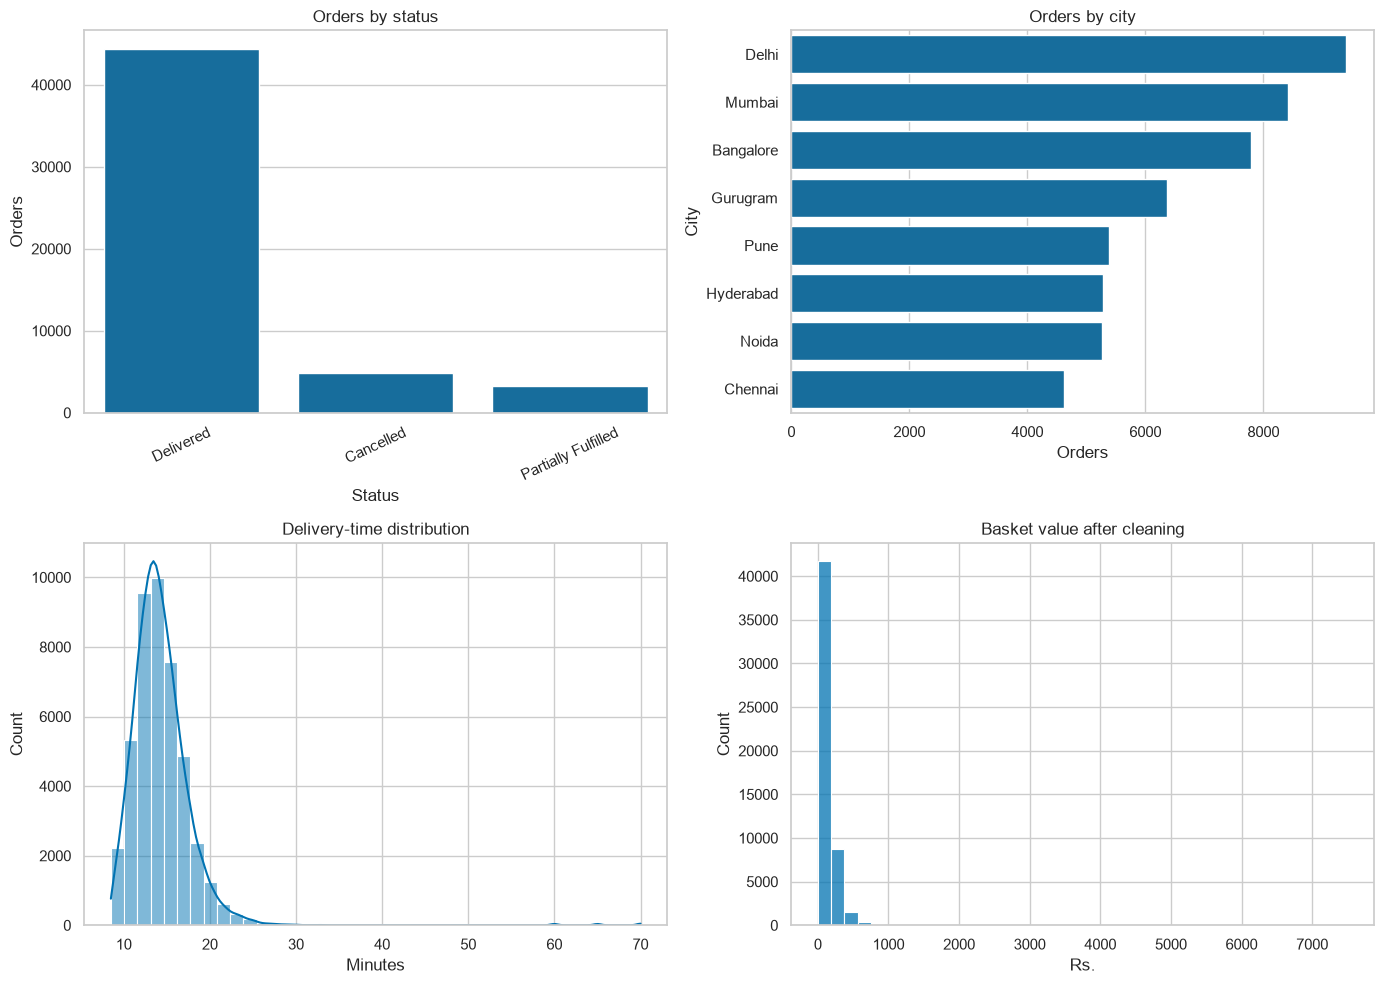

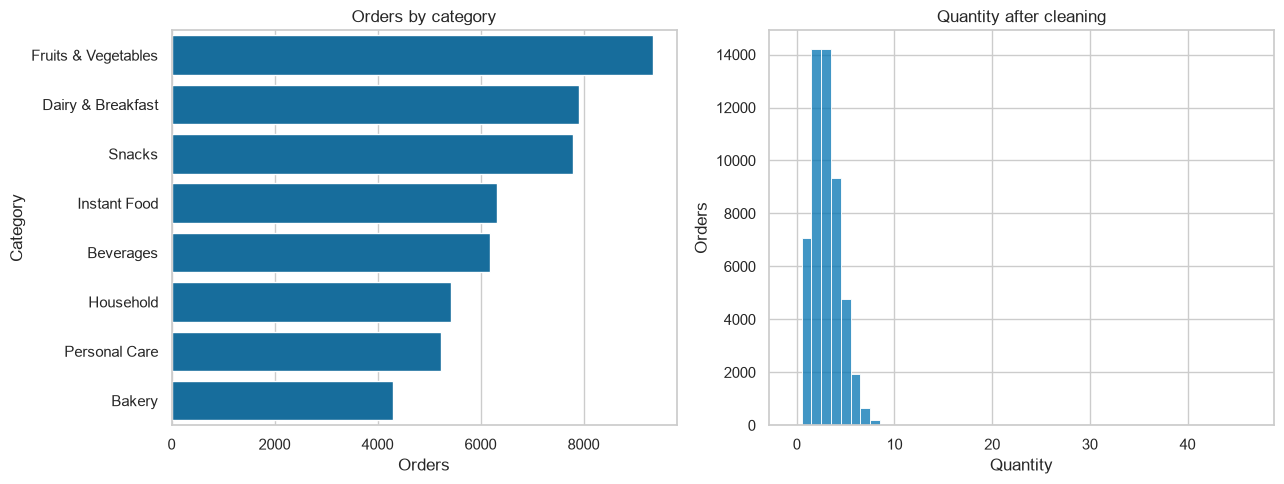

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
sns.countplot(data=cleaned, x="order_status", order=cleaned["order_status"].value_counts().index, ax=axes[0, 0])
axes[0, 0].set(title="Orders by status", xlabel="Status", ylabel="Orders")
axes[0, 0].tick_params(axis="x", rotation=25)
sns.countplot(data=cleaned, y="city", order=cleaned["city"].value_counts().index, ax=axes[0, 1])
axes[0, 1].set(title="Orders by city", xlabel="Orders", ylabel="City")
sns.histplot(data=df_delivered, x="actual_delivery_mins", bins=40, kde=True, ax=axes[1, 0])
axes[1, 0].set(title="Delivery-time distribution", xlabel="Minutes")
sns.histplot(data=cleaned, x="order_value", bins=40, ax=axes[1, 1])
axes[1, 1].set(title="Basket value after cleaning", xlabel="Rs.")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.countplot(data=cleaned, y="category", order=cleaned["category"].value_counts().index, ax=axes[0])
axes[0].set(title="Orders by category", xlabel="Orders", ylabel="Category")
sns.histplot(data=cleaned, x="quantity", discrete=True, ax=axes[1])
axes[1].set(title="Quantity after cleaning", xlabel="Quantity", ylabel="Orders")
plt.tight_layout()
plt.show()


### Conclusion from above graph :-

Compare order counts with the delivery-time distribution. A long right tail means MAE and RMSE should both be reported; an average is not a guaranteed ETA.

## Time-Based Analysis :-


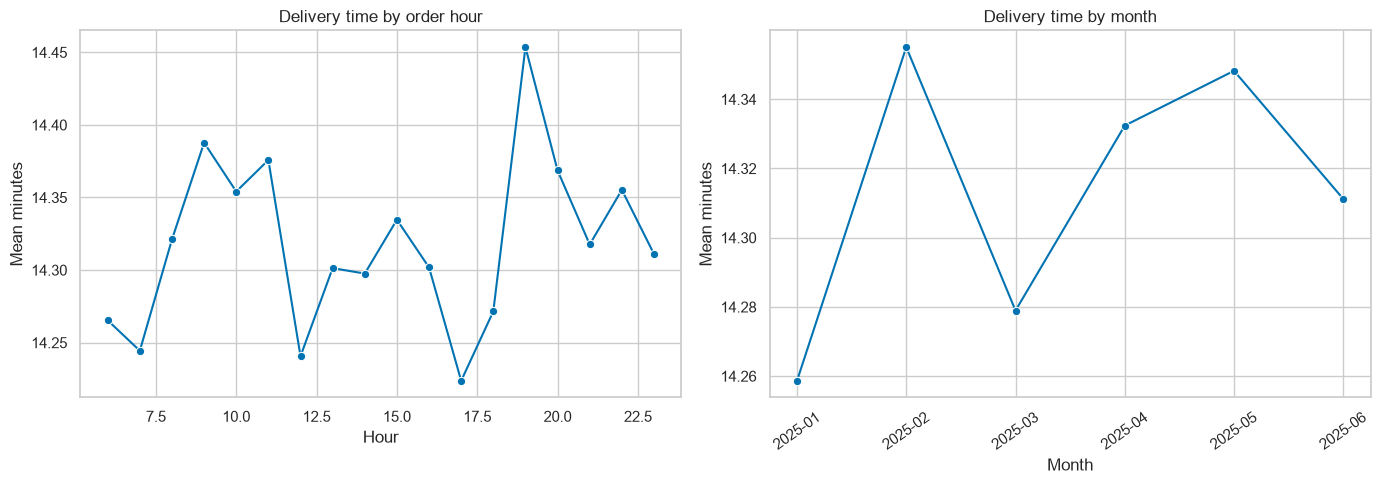

,mean,median,count
order_hour,,,
6,14.27,13.90,2291
7,14.24,13.80,1112
8,14.32,13.80,1470
9,14.39,14.05,1844
10,14.35,13.80,2237
11,14.38,13.90,2690
12,14.24,13.90,3012
13,14.30,13.85,3240
14,14.30,13.90,5588


In [8]:
df_delivered["order_hour"] = pd.to_numeric(df_delivered["order_hour"], errors="coerce")
df_delivered["order_month"] = df_delivered["order_date"].dt.to_period("M").astype(str)
hourly = df_delivered.groupby("order_hour", dropna=True)["actual_delivery_mins"].agg(["mean", "median", "count"])
monthly = df_delivered.groupby("order_month")["actual_delivery_mins"].agg(["mean", "median", "count"])
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.lineplot(data=hourly.reset_index(), x="order_hour", y="mean", marker="o", ax=axes[0])
axes[0].set(title="Delivery time by order hour", xlabel="Hour", ylabel="Mean minutes")
sns.lineplot(data=monthly.reset_index(), x="order_month", y="mean", marker="o", ax=axes[1])
axes[1].set(title="Delivery time by month", xlabel="Month", ylabel="Mean minutes")
axes[1].tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()
display(hourly.round(2))


### Conclusion from above graphs :-

Review time-related changes. Hyperparameter selection below uses a chronological validation window and keeps a later-date holdout untouched until final scoring.

## Bivariate Analysis :-


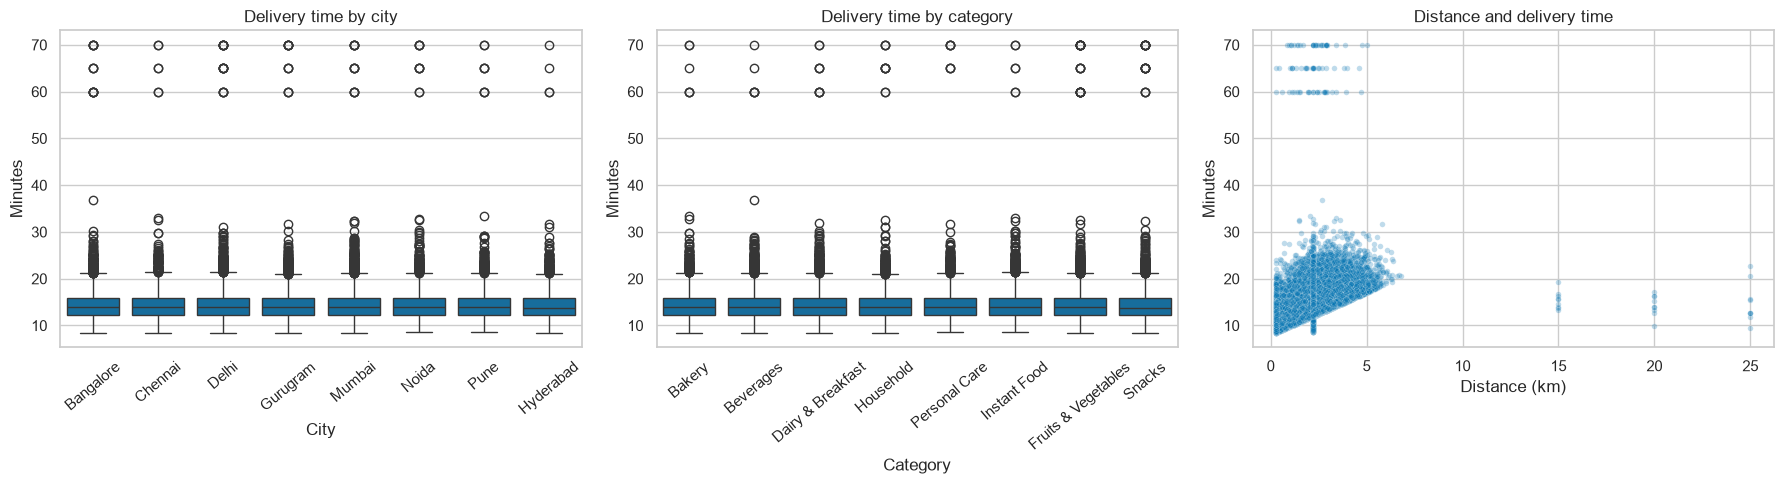

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
city_order = df_delivered.groupby("city")["actual_delivery_mins"].median().sort_values(ascending=False).index
sns.boxplot(data=df_delivered, x="city", y="actual_delivery_mins", order=city_order, ax=axes[0])
axes[0].set(title="Delivery time by city", xlabel="City", ylabel="Minutes")
axes[0].tick_params(axis="x", rotation=40)
category_order = df_delivered.groupby("category")["actual_delivery_mins"].median().sort_values(ascending=False).index
sns.boxplot(data=df_delivered, x="category", y="actual_delivery_mins", order=category_order, ax=axes[1])
axes[1].set(title="Delivery time by category", xlabel="Category", ylabel="Minutes")
axes[1].tick_params(axis="x", rotation=40)
sns.scatterplot(data=df_delivered, x="distance_km", y="actual_delivery_mins", alpha=0.25, s=16, ax=axes[2])
axes[2].set(title="Distance and delivery time", xlabel="Distance (km)", ylabel="Minutes")
plt.tight_layout()
plt.show()


### Conclusion from above graph :-

Patterns across groups are descriptive. Validate them on later dates before treating them as predictive.

## Delivery Partner Performance :-

Partner assignment occurs after checkout, so partner IDs may be inspected for retrospective operations but are excluded from the model.


In [10]:
partner_summary = (
    df_delivered.groupby("delivery_partner_id")["actual_delivery_mins"]
    .agg(orders="count", mean_minutes="mean", median_minutes="median")
    .query("orders >= 20")
    .sort_values("median_minutes", ascending=False)
)
display(partner_summary.round(2).head(20))


,orders,mean_minutes,median_minutes
delivery_partner_id,,,
DP1129,107,14.80,14.80
DP1389,99,14.97,14.70
DP1033,97,14.81,14.70
DP1089,110,15.09,14.70
DP1180,114,14.65,14.60
DP1016,121,15.45,14.60
DP1002,97,14.69,14.60
DP1235,133,14.77,14.50
DP1106,99,14.85,14.50


## Category Preference by City :-

category,Bakery,Beverages,Dairy & Breakfast,Fruits & Vegetables,Household,Instant Food,Personal Care,Snacks
city,,,,,,,,
Bangalore,651,880,1188,1395,752,918,825,1175
Chennai,398,530,686,835,511,528,456,669
Delhi,777,1078,1419,1736,972,1130,924,1368
Gurugram,512,757,984,1096,661,740,644,971
Hyderabad,433,623,775,956,544,707,474,765
Mumbai,681,1032,1265,1462,876,1009,850,1244
Noida,432,600,783,923,547,667,510,799
Pune,414,681,807,936,564,629,546,800


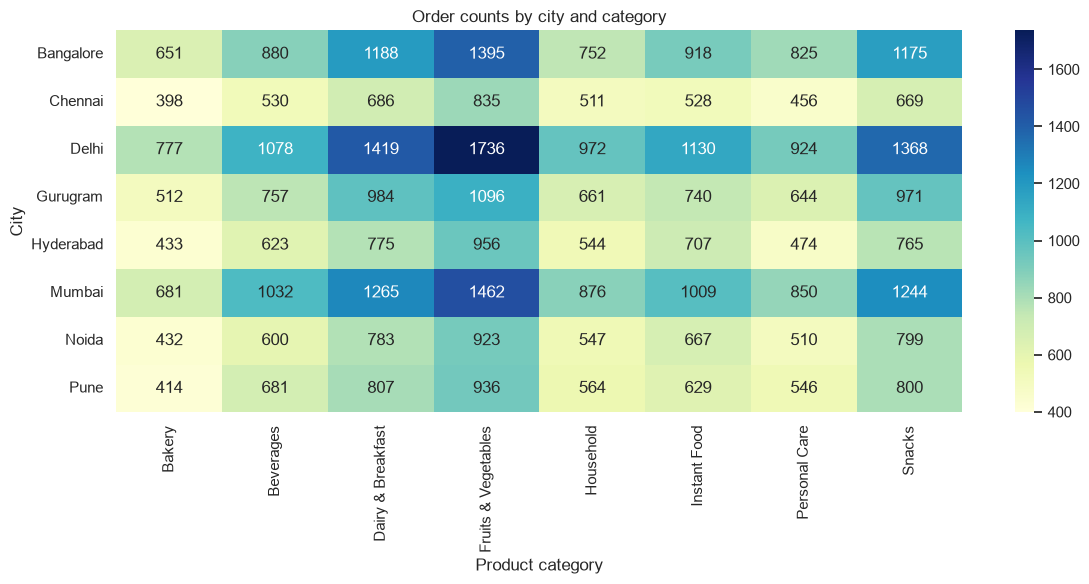

In [11]:
category_city = pd.crosstab(cleaned["city"], cleaned["category"])
display(category_city)
plt.figure(figsize=(12, 6))
sns.heatmap(category_city, annot=True, fmt="d", cmap="YlGnBu")
plt.title("Order counts by city and category")
plt.xlabel("Product category")
plt.ylabel("City")
plt.tight_layout()
plt.show()


## Correlation Between Operational Metrics :-

Correlation is descriptive, not causal. Promise time, IDs, delivery status, rating, partner assignment, and stockout outcomes are not checkout-time model features.


,quantity,unit_price,order_value,distance_km,actual_delivery_mins,customer_rating,stockout_flag
quantity,1.00,-0.00,0.47,0.01,0.00,0.00,NaN
unit_price,-0.00,1.00,0.76,0.00,0.01,0.01,NaN
order_value,0.47,0.76,1.00,0.01,0.01,0.01,NaN
distance_km,0.01,0.00,0.01,1.00,0.45,-0.04,NaN
actual_delivery_mins,0.00,0.01,0.01,0.45,1.00,-0.05,NaN
customer_rating,0.00,0.01,0.01,-0.04,-0.05,1.00,NaN
stockout_flag,NaN,NaN,NaN,NaN,NaN,NaN,NaN


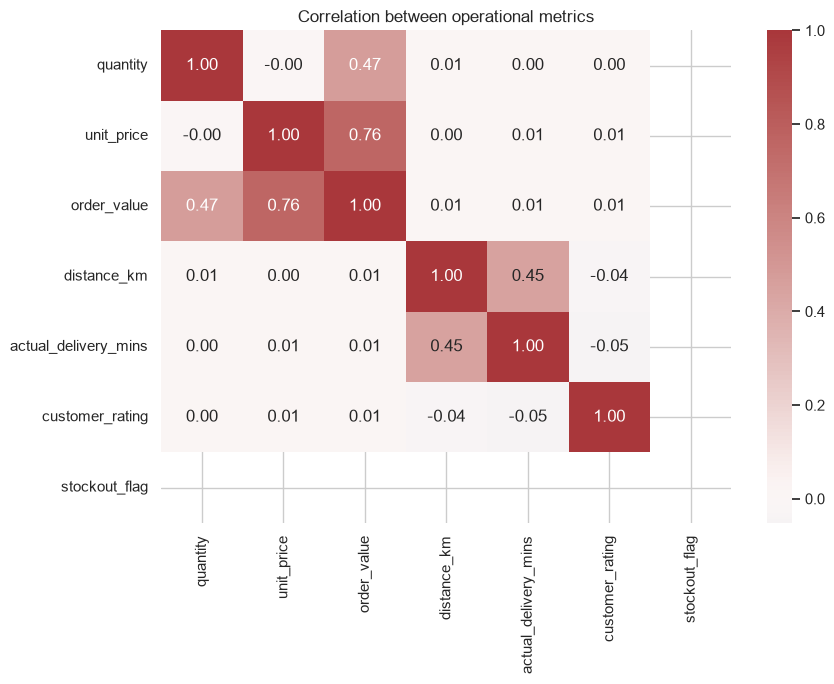

Checkout-time feature count: 22
Features: ['city', 'dark_store_id', 'category', 'payment_mode', 'order_hour', 'order_hour_sin', 'order_hour_cos', 'order_day_of_week', 'order_day_of_week_sin', 'order_day_of_week_cos', 'order_month', 'order_month_sin', 'order_month_cos', 'order_day_of_year', 'is_weekend', 'order_hour_missing', 'quantity_missing', 'distance_missing', 'quantity', 'unit_price', 'order_value', 'distance_km']
Valid delivered model rows: 44,402


In [12]:
numeric_columns = [
    column for column in ["quantity", "unit_price", "order_value", "distance_km",
                          "actual_delivery_mins", "customer_rating", "stockout_flag"]
    if column in df_delivered
]
numeric_data = df_delivered[numeric_columns].apply(pd.to_numeric, errors="coerce")
display(numeric_data.corr().round(2))
plt.figure(figsize=(9, 7))
sns.heatmap(numeric_data.corr(), annot=True, fmt=".2f", cmap="vlag", center=0)
plt.title("Correlation between operational metrics")
plt.tight_layout()
plt.show()

X, y, dates = prepare_training_data(raw)
print("Checkout-time feature count:", len(FEATURES))
print("Features:", FEATURES)
print("Valid delivered model rows:", f"{len(X):,}")


## Tuned Delivery-Time Models :-

Linear regression (with tuned Ridge regularization), Decision Tree, Random Forest, and XGBoost are tuned on a deterministic sample of up to 12,000 earlier training rows and scored against the full chronological validation window. Scores are reported on the separate later-date holdout; the holdout is not used to select hyperparameters.


In [13]:
results, best_model = train_and_save(
    raw,
    model_dir=PROJECT_ROOT / "models",
    report_dir=PROJECT_ROOT / "reports",
    tuning_trials=5,
)
display(results.style.format({
    "mae_minutes": "{:.3f}",
    "rmse_minutes": "{:.3f}",
    "r2": "{:.3f}",
    "tuning_validation_mae": "{:.3f}",
}))
print("Selected model by holdout MAE:", best_model)
print("Saved API artifact:", PROJECT_ROOT / "models" / "delivery_time_model.joblib")


AttributeError: The '.style' accessor requires jinja2

## Final Conclusion :-

- Compare holdout MAE (minutes), RMSE, and R²; tuning does not guarantee improvement on future dates.
- Model inputs are limited to checkout-time fields. The dataset does not provide live traffic, weather, or courier availability.
- Treat predictions as historical estimates rather than live ETAs or guaranteed delivery times.
- Retrain from the project root with `python train.py --tuning-trials 5`.
